Indicador Smart Money Concepts LuxAlgo  
Coincide con el resultado obtenido en Tradingview consumiendo Bitcoin/USD de la plataforma Binance  
Intervalo: 1d  
Período: 01/09/2024 - 19/06/2026  

In [ ]:
import sys
from datetime import datetime
import pandas_ta_classic as ta

project_root = r"D:\Work\DeepVision\nexora-trading-framework"
if project_root not in sys.path:
    sys.path.append(project_root)

from config import settings
from app.brokers.factory import BrokerFactory, AvailableBrokers
from app.brokers.market_data.provider import DataFormat
from app.visualization.plots import (plot_bos_choch,
    plot_smc_order_blocks, plot_smc_swing_points, plot_smc_strong_weak_hl,
    plot_smc_equal_hl,
)
from app.tradingview.smc_indicator import SMCIndicator
from app.tradingview.types import SMCConfig
from app.tradingview.plotting import plot_trend_candles
from datetime import timedelta
import pandas_luarix  # registers the .structure / .smc DataFrame accessors

In [3]:
# Available SYMBOLS: BCHUSDT, BTCUSDT, ETHUSDT, BNBUSDT, ADAUSDT, SOLUSDT, XRPUSDT, DOTUSDT, DOGEUSDT, AVAXUSDT, MATICUSDT, EURUSDT

SYMBOL = settings.PIPELINE_SYMBOL
INTERVAL = settings.PIPELINE_INTERVAL
CAPITAL = settings.CAPITAL
STOP_LOSS_PERCENT = settings.STOP_LOSS_PERCENT
STOP_LIMIT_PERCENT = settings.STOP_LIMIT_PERCENT
START = settings.START
END = datetime(2024, 1, 1)

In [4]:
binance_provider = BrokerFactory.get_broker(AvailableBrokers.BINANCE, False)

In [5]:
monthly_candles = binance_provider.market_data_provider.get_historical_candles(SYMBOL, start=START, end=END, interval=INTERVAL, format=DataFormat.OHLCV)


2329 [1704067200000, '42283.58000000', '44184.10000000', '42180.77000000', '44179.55000000', '27174.29903000', 1704153599999, '1169995682.02800140', 1114623, '14331.73180000', '617352094.56051940', '0']


In [6]:
atr_precomputed = ta.atr(monthly_candles["high"], monthly_candles["low"], monthly_candles["close"], 14)
ohlcv_df = monthly_candles.reset_index(drop=True)
config   = SMCConfig(swing_length=50, equal_length=10)
result   = SMCIndicator(config).run(ohlcv_df, precomputed_atr=atr_precomputed)
#update_smc_results_equals(df=ohlcv_df, result=result, tolerance_pct=0.005)
external = [s for s in result.structure_events if not s.internal]

print(f"Total barras: {len(ohlcv_df)}  |  EQH: {len(result.equal_highs)}  EQL: {len(result.equal_lows)}")

Total barras: 2329  |  EQH: 1  EQL: 2


In [7]:
# Comparación puro-default vs puro-default: SMCIndicator(SMCConfig()) sin
# precomputed_atr (usa su ATR(200) interno) vs pandas_luarix con sus propios
# defaults (equal_length=3 -> length=3, atr_period=200) — deben coincidir exacto.
reference_result = SMCIndicator(SMCConfig()).run(ohlcv_df)

eqh_groups = ohlcv_df.structure.equal_high(include_mitigated=True)
eql_groups = ohlcv_df.structure.equal_low(include_mitigated=True)

print(f"Reference EQH: {len(reference_result.equal_highs)}  |  pandas_luarix EQH groups: {len(eqh_groups)}")
print(f"Reference EQL: {len(reference_result.equal_lows)}  |  pandas_luarix EQL groups: {len(eql_groups)}")

print()
print("Reference equal_highs[0]:")
print(reference_result.equal_highs[0])
print()
print("pandas_luarix equal_high()[0]:")
eqh_groups[0]

Reference EQH: 20  |  pandas_luarix EQH groups: 20
Reference EQL: 18  |  pandas_luarix EQL groups: 18

Reference equal_highs[0]:
EqualLevel(first_index=187, second_index=200, price=np.float64(11710.0), bullish=False, first_time=Timestamp('2018-02-20 00:00:00+0000', tz='UTC'), second_time=Timestamp('2018-03-05 00:00:00+0000', tz='UTC'), c1=date                 2018-02-20 00:00:00+00:00
open                                  11147.11
high                                  11786.01
low                                   11100.59
close                                 11200.99
volume                            48153.354288
close_time    2018-02-20 23:59:59.999000+00:00
Name: 187, dtype: object, c2=date                 2018-03-05 00:00:00+00:00
open                                   11515.0
high                                   11710.0
low                                   11415.01
close                                  11454.0
volume                            15144.231063
close_time    2018-

,date,open,high,low,close,volume,close_time,mitigated
187,2018-02-20 00:00:00+00:00,11147.11,11786.01,11100.59,11200.99,48153.354288,2018-02-20 23:59:59.999000+00:00,True
200,2018-03-05 00:00:00+00:00,11515.00,11710.00,11415.01,11454.00,15144.231063,2018-03-05 23:59:59.999000+00:00,True


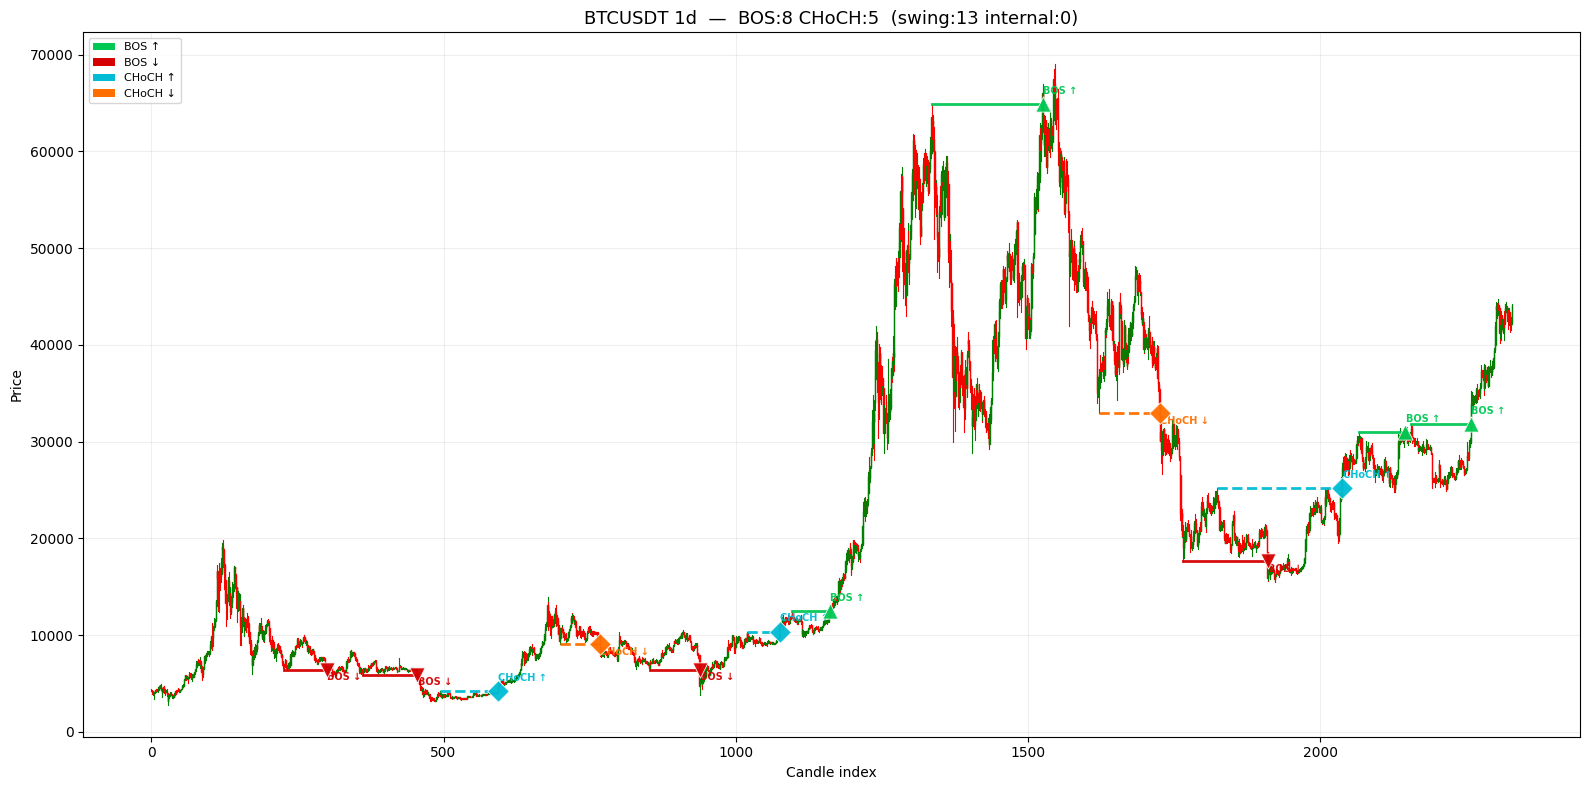

In [8]:
plot_bos_choch(
    df=ohlcv_df,
    events=external,
    title=f"{SYMBOL} {INTERVAL}",
)

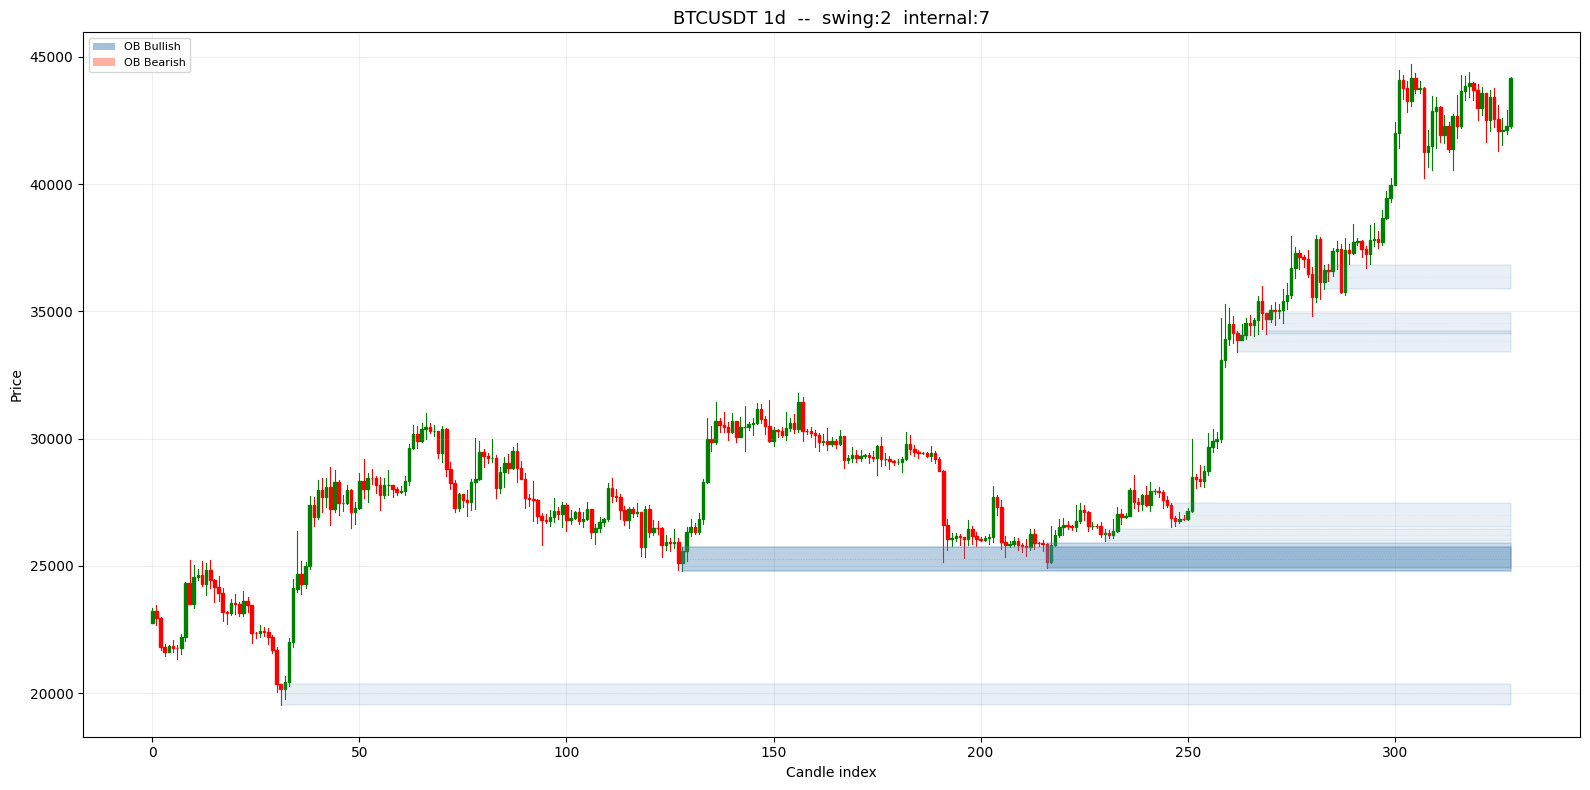

In [29]:
plot_smc_order_blocks(
    df=ohlcv_df,
    swing_obs=result.swing_order_blocks,
    internal_obs=result.internal_order_blocks,
    title=f"{SYMBOL} {INTERVAL}",
)

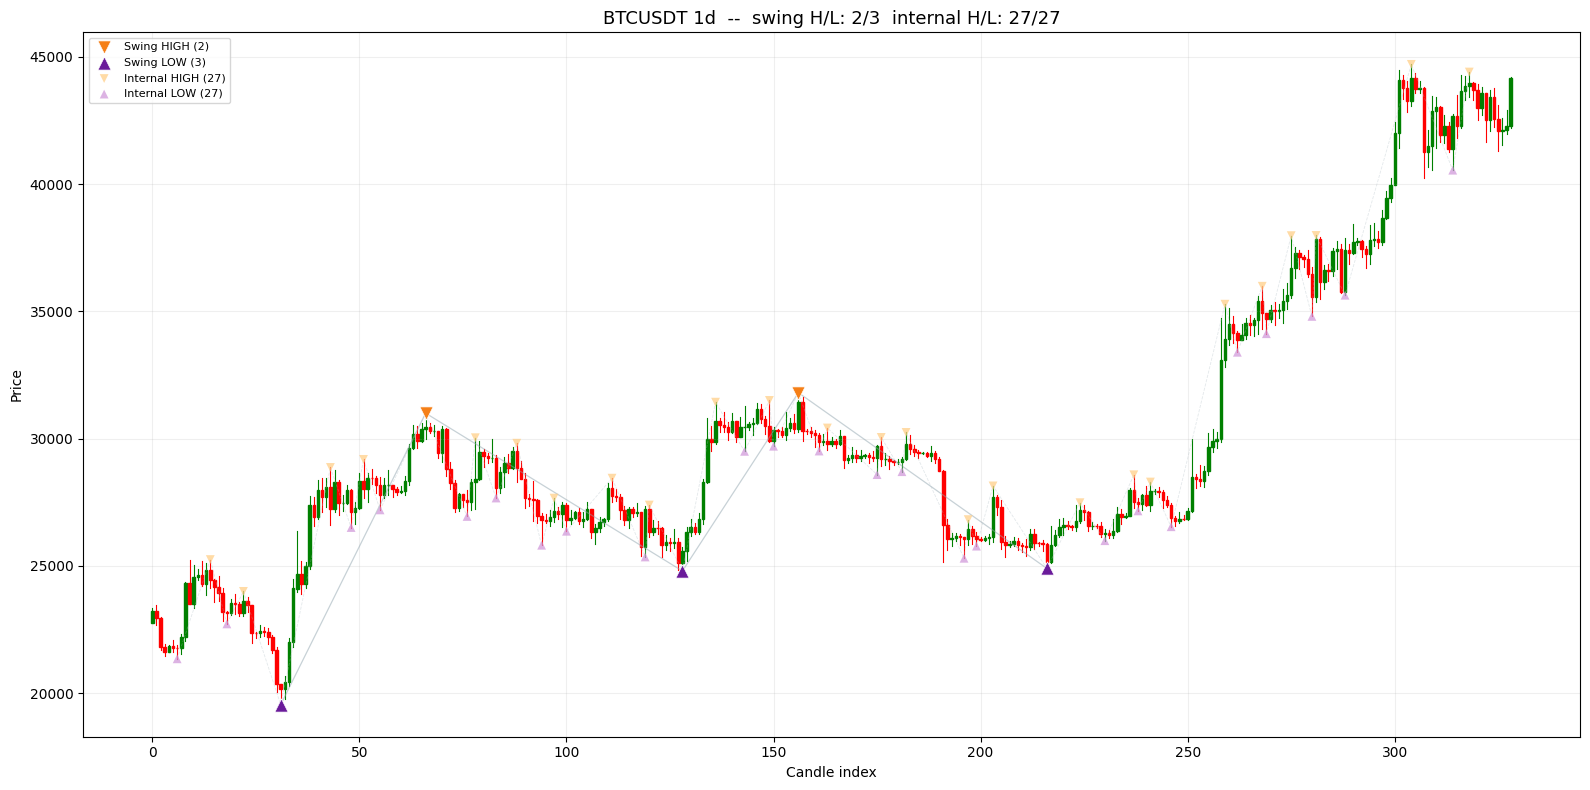

In [30]:
plot_smc_swing_points(
    df=ohlcv_df,
    result=result,
    config=config,
    title=f"{SYMBOL} {INTERVAL}",
)

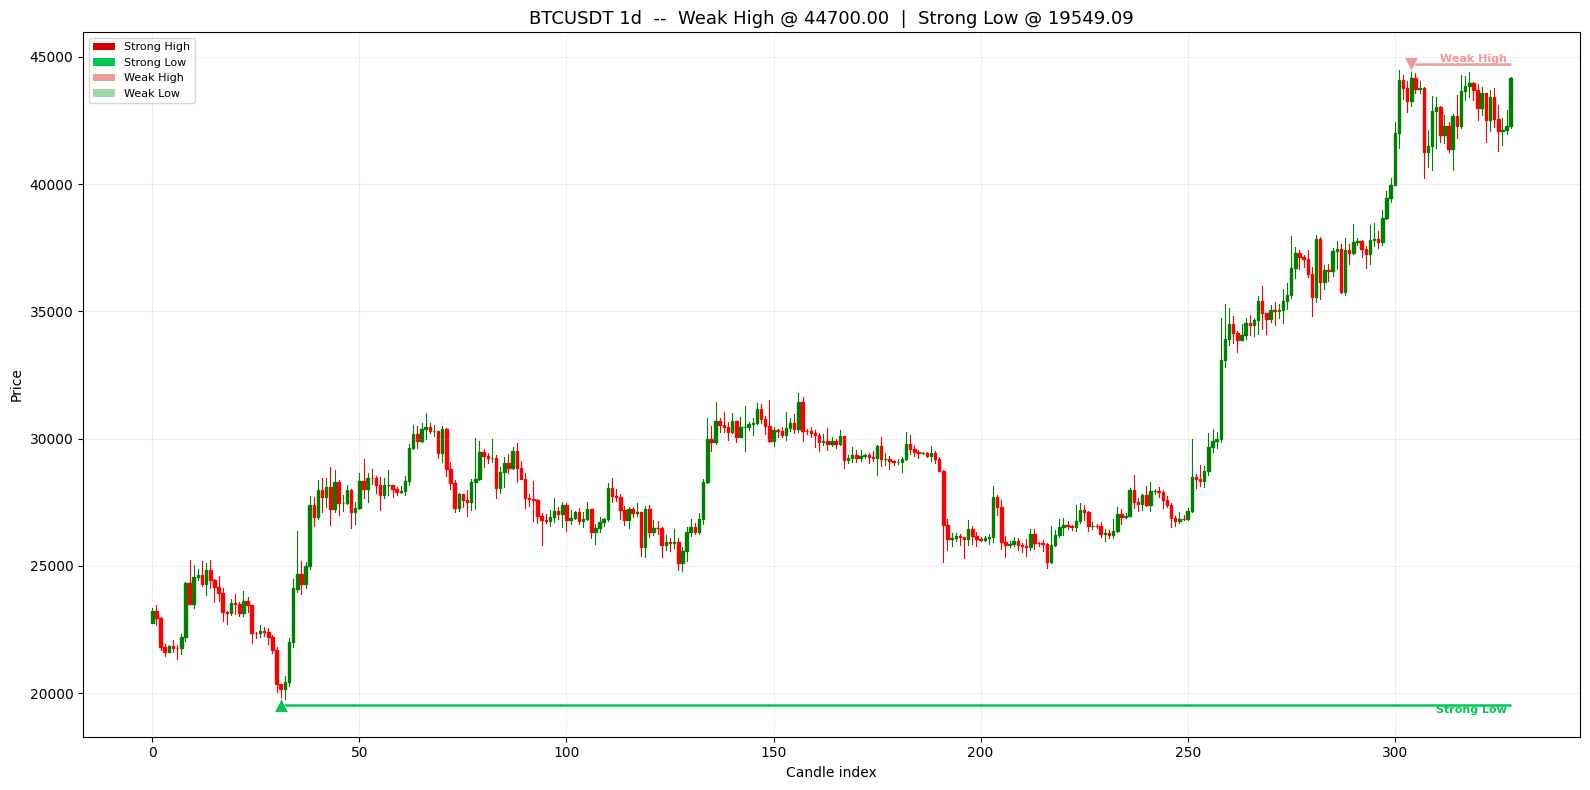

In [31]:
plot_smc_strong_weak_hl(
    df=ohlcv_df,
    result=result,
    swing_only=True,   # False para incluir internal structure
    title=f"{SYMBOL} {INTERVAL}",
)

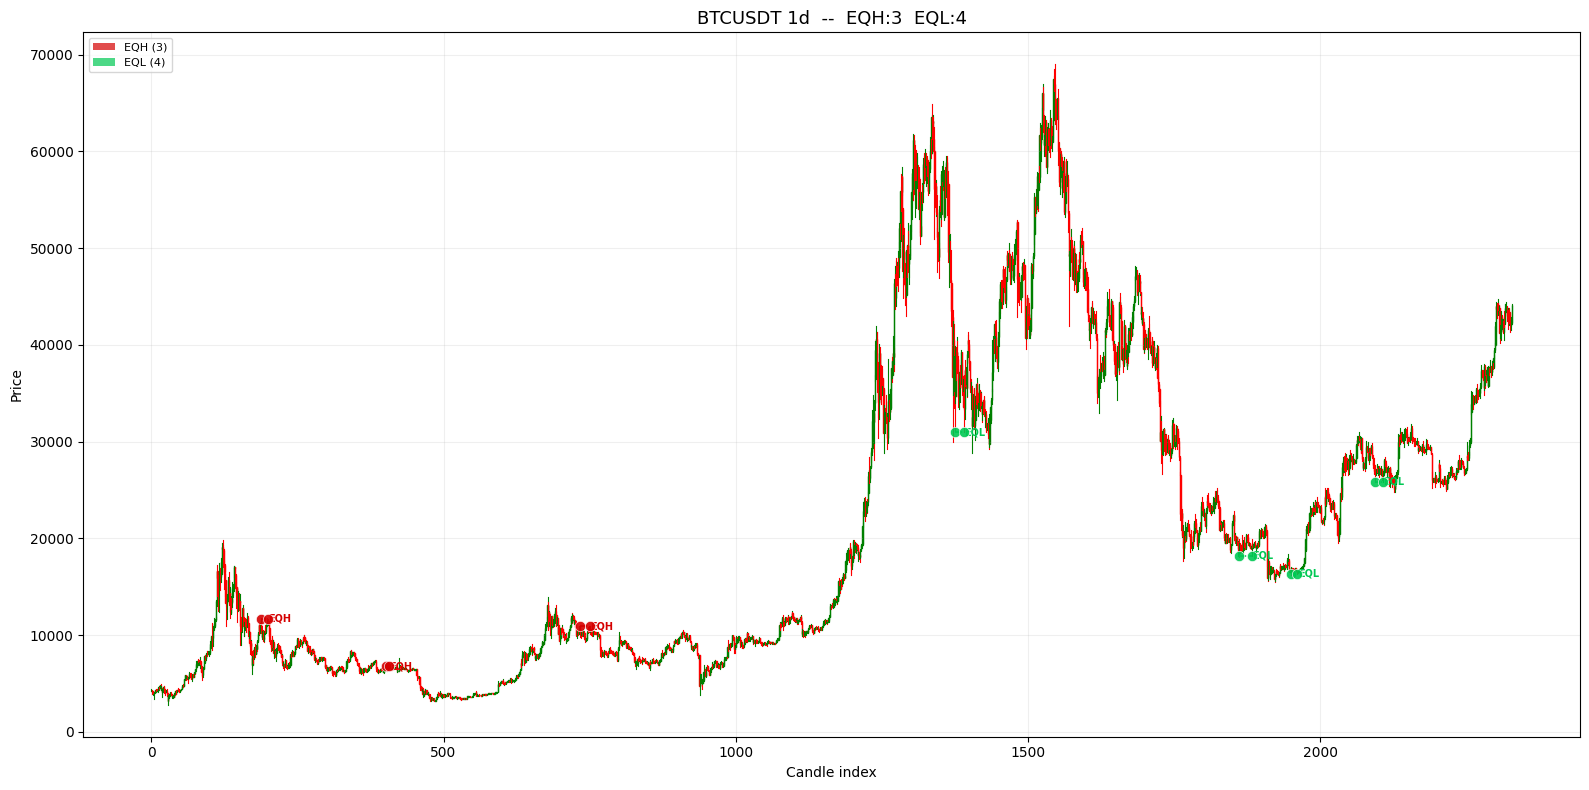

In [57]:
plot_smc_equal_hl(
    df=ohlcv_df,
    result=result,
    title=f"{SYMBOL} {INTERVAL}",
)

In [ ]:
plot_trend_candles(ohlcv_df, result.trends, title=f"{SYMBOL} {INTERVAL}")

NameError: name 'interval' is not defined